In [12]:
pip install tensorflow gymnasium numpy

In [13]:
import gymnasium as gym
import numpy as np
import tensorflow as tf
from tensorflow import keras
from collections import deque
import random

In [14]:
env = gym.make("CartPole-v1")

state_size = env.observation_space.shape[0]
action_size = env.action_space.n

print("State size:", state_size)
print("Action size:", action_size)

State size: 4
Action size: 2


In [16]:
def build_q_network(state_size, action_size):

    state_size = int(state_size)
    action_size = int(action_size)

    model = keras.Sequential([
        keras.Input(shape=(state_size,)),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(units=action_size, activation="linear")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="mse"
    )

    return model


# Ensure dimensions are standard Python integers
state_size = int(env.observation_space.shape[0])
action_size = int(env.action_space.n)

# Create networks
q_network = build_q_network(state_size, action_size)
target_network = build_q_network(state_size, action_size)

# Initialize target network with the same weights
target_network.set_weights(q_network.get_weights())

print("State size:", state_size)
print("Action size:", action_size)
print("Q-network created successfully!")

State size: 4
Action size: 2
Q-network created successfully!


In [17]:
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

def choose_action(state):

    if np.random.random() < epsilon:
        return env.action_space.sample()

    q_values = q_network.predict(
        state[np.newaxis, :],
        verbose=0
    )

    return np.argmax(q_values[0])

In [18]:
gamma = 0.99
batch_size = 64

def replay():

    if len(memory) < batch_size:
        return

    minibatch = random.sample(memory, batch_size)

    states = np.array([item[0] for item in minibatch])
    actions = np.array([item[1] for item in minibatch])
    rewards = np.array([item[2] for item in minibatch])
    next_states = np.array([item[3] for item in minibatch])
    dones = np.array([item[4] for item in minibatch])

    current_q = q_network.predict(states, verbose=0)
    next_q = target_network.predict(next_states, verbose=0)

    targets = current_q.copy()

    for i in range(batch_size):

        if dones[i]:
            targets[i, actions[i]] = rewards[i]
        else:
            targets[i, actions[i]] = (
                rewards[i] + gamma * np.max(next_q[i])
            )

    q_network.train_on_batch(states, targets)

In [21]:
from collections import deque

# Experience replay memory
memory = deque(maxlen=20000)

# Store experiences
def remember(state, action, reward, next_state, done):
    memory.append((state, action, reward, next_state, done))

In [ ]:
episodes = 200
scores = []

for episode in range(episodes):

    state, _ = env.reset()
    state = np.asarray(state, dtype=np.float32)

    total_reward = 0
    done = False

    while not done:

        action = choose_action(state)

        next_state, reward, terminated, truncated, _ = env.step(action)
        next_state = np.asarray(next_state, dtype=np.float32)

        done = terminated or truncated

        # Store experience in replay memory
        remember(
            state, action, reward, next_state, done
        )

        # Train the Q-network using replay memory
        replay()

        state = next_state
        total_reward += reward

    scores.append(total_reward)

    # Reduce exploration gradually
    epsilon = max(epsilon_min, epsilon * epsilon_decay)

    # Update target network every 5 episodes
    if (episode + 1) % 5 == 0:
        target_network.set_weights(q_network.get_weights())

    print(
        f"Episode {episode + 1}/{episodes} | "
        f"Score: {total_reward:.0f} | "
        f"Epsilon: {epsilon:.3f}"
    )

env.close()

Episode 1/200 | Score: 52 | Epsilon: 0.995
Episode 2/200 | Score: 42 | Epsilon: 0.990
Episode 3/200 | Score: 19 | Epsilon: 0.985
Episode 4/200 | Score: 31 | Epsilon: 0.980
Episode 5/200 | Score: 26 | Epsilon: 0.975
Episode 6/200 | Score: 18 | Epsilon: 0.970
Episode 7/200 | Score: 16 | Epsilon: 0.966
Episode 8/200 | Score: 45 | Epsilon: 0.961
Episode 9/200 | Score: 11 | Epsilon: 0.956
Episode 10/200 | Score: 31 | Epsilon: 0.951
Episode 11/200 | Score: 24 | Epsilon: 0.946
Episode 12/200 | Score: 10 | Epsilon: 0.942
Episode 13/200 | Score: 30 | Epsilon: 0.937
Episode 14/200 | Score: 51 | Epsilon: 0.932
Episode 15/200 | Score: 21 | Epsilon: 0.928
Episode 16/200 | Score: 18 | Epsilon: 0.923
Episode 17/200 | Score: 25 | Epsilon: 0.918
Episode 18/200 | Score: 17 | Epsilon: 0.914
Episode 19/200 | Score: 15 | Epsilon: 0.909
Episode 20/200 | Score: 14 | Epsilon: 0.905
Episode 21/200 | Score: 14 | Epsilon: 0.900
Episode 22/200 | Score: 22 | Epsilon: 0.896
Episode 23/200 | Score: 20 | Epsilon: 0.8

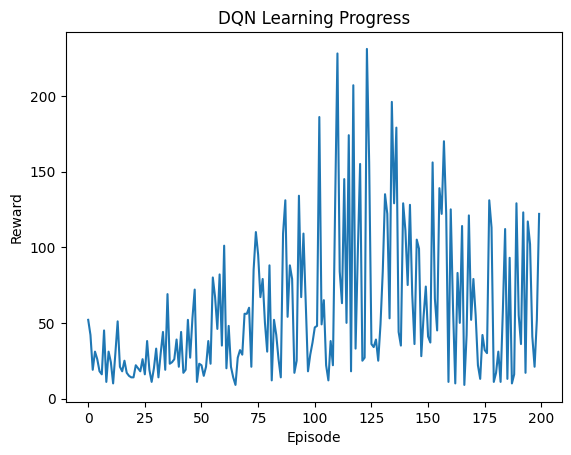

In [23]:
import matplotlib.pyplot as plt

plt.plot(scores)
plt.xlabel("Episode")
plt.ylabel("Reward")
plt.title("DQN Learning Progress")
plt.show()